<a href="https://colab.research.google.com/github/maliboo-wow/ml-lab/blob/main/%D0%9B%D0%A09_%D0%91%D1%96%D0%B1%D1%96%D0%BA%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A23_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 9
## Рекомендаційні системи: SVD та KNNBasic

**ПІБ студента:** Бібікова Анастасія  
**Група:** ФІТ 3-12  
**Дата:** 26.11.2026

> **Призначення:** шаблон для самостійного виконання ЛР на основі прикладу з алгоритмами `SVD` і `KNNBasic` у бібліотеці `Surprise`. Комірки з позначкою **TODO** потрібно заповнити власним кодом. Це не готовий розв’язок і не заміна офіційної умови роботи.

**Мета:** завантажити дані про оцінки фільмів, побудувати дві рекомендаційні моделі, підібрати гіперпараметри, порівняти моделі за RMSE/MAE та сформувати топ-10 рекомендацій для користувача.

**Дані:** вбудований набір `MovieLens 100K` (`ml-100k`) із бібліотеки `Surprise`.

**Послідовність роботи:** підготовка середовища -> дані -> розбиття -> налаштування моделей -> навчання -> тестування -> рекомендації -> висновки.

## 1. Підготовка середовища

Комбінація бібліотек для **Google Colab із Python 3.13**. Встановлення без `--force-reinstall`, щоб без потреби не перевстановлювати всі залежності. Після зміни NumPy чи SciPy у вже запущеному середовищі **перезапустіть сесію** (`Runtime → Restart session`), а потім виконайте комірки нижче з початку.

In [1]:
%pip install -q \
    numpy==2.2.6 \
    scipy==1.15.3 \
    scikit-learn==1.6.1 \
    pandas==2.2.3 \
    scikit-surprise==1.1.5

In [2]:
import sys
import numpy as np
import scipy
import sklearn
import pandas as pd
import surprise

from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split as sklearn_train_test_split

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('Surprise:', surprise.__version__)

Python: 3.13.18
NumPy: 2.4.6
SciPy: 1.15.3
scikit-learn: 1.6.1
pandas: 2.2.3
Surprise: 1.1.5


## 2. Завантаження та первинний аналіз даних

1. Завантажте вбудований набір `ml-100k`.
2. Перетворіть оцінки у `pandas.DataFrame` з колонками `user_id`, `item_id`, `rating`, `timestamp`.
3. Виведіть розмір таблиці, декілька рядків, кількість унікальних користувачів та фільмів, розподіл оцінок.

**Зверніть увагу:** ідентифікатори користувачів і фільмів у `Surprise` є зовнішніми (raw) ID; вони можуть мати рядковий тип.

In [3]:
# Завантаження даних (готова частина шаблону)
data = Dataset.load_builtin('ml-100k', prompt=False)

ratings_df = pd.DataFrame(
    data.raw_ratings,
    columns=['user_id', 'item_id', 'rating', 'timestamp']
)

print('Розмір:', ratings_df.shape)
display(ratings_df.head())

Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k
Розмір: (100000, 4)


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


Унікальних користувачів: 943
Унікальних фільмів: 1682
Мінімальна оцінка: 1.0
Максимальна оцінка: 5.0
Середня оцінка: 3.53

Пропущені значення:
user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64

Заповненість матриці: 6.30%
Оцінок на користувача: мін = 20 , медіана = 65 , макс = 737


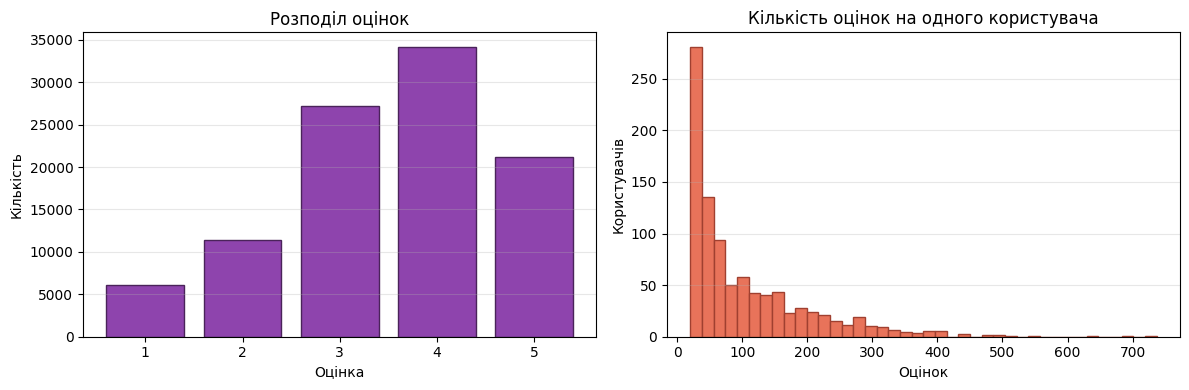

In [4]:
# TODO 2.1 — Дослідіть набір даних:
# - кількість унікальних користувачів;
# - кількість унікальних фільмів;
# - мінімальне, максимальне, середнє значення rating;
# - пропущені значення (за наявності).

# Ваш код:
import matplotlib.pyplot as plt

n_users = ratings_df['user_id'].nunique()
n_items = ratings_df['item_id'].nunique()

print('Унікальних користувачів:', n_users)
print('Унікальних фільмів:', n_items)
print('Мінімальна оцінка:', ratings_df['rating'].min())
print('Максимальна оцінка:', ratings_df['rating'].max())
print('Середня оцінка:', round(ratings_df['rating'].mean(), 3))

print('\nПропущені значення:')
print(ratings_df.isnull().sum())

# наскільки заповнена матриця користувач-фільм
density = len(ratings_df) / (n_users * n_items)
print('\nЗаповненість матриці: {:.2%}'.format(density))

# скільки оцінок поставив кожен користувач
user_counts = ratings_df.groupby('user_id').size()
print('Оцінок на користувача: мін =', user_counts.min(), ', медіана =', int(user_counts.median()), ', макс =', user_counts.max())

counts = ratings_df['rating'].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(counts.index, counts.values, color='#8E44AD', edgecolor='#4A235A')
ax[0].set_title('Розподіл оцінок')
ax[0].set_xlabel('Оцінка')
ax[0].set_ylabel('Кількість')
ax[0].grid(axis='y', alpha=0.3)

ax[1].hist(user_counts, bins=40, color='#E8735A', edgecolor='#A04030')
ax[1].set_title('Кількість оцінок на одного користувача')
ax[1].set_xlabel('Оцінок')
ax[1].set_ylabel('Користувачів')
ax[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Короткі спостереження щодо даних:**

У наборі 100 000 оцінок від 943 користувачів для 1682 фільмів, пропусків немає. Матриця користувач-фільм заповнена лише на 6.3%, тобто більшість фільмів кожен користувач не дивився, і саме ці пропуски моделі мають передбачити.

Оцінки цілі від 1 до 5, середня 3.53. Найчастіше ставлять 4, потім 3, а низьких оцінок (1 і 2) мало, тому розподіл зсунутий у бік високих оцінок. Кожен користувач оцінив щонайменше 20 фільмів (медіана 65), але є кілька дуже активних, у яких понад 500 оцінок.

## 3. Розбиття на навчальну та тестову вибірки

Виконайте випадкове розбиття **80% / 20%** із `random_state=42` за прикладом. Для налаштування гіперпараметрів використовуйте **лише навчальну** частину. Тестова вибірка має залишатися недоторканою до фінальної оцінки.

In [5]:
# TODO 3.1 — Створіть train_df та test_df із ratings_df.
# Використайте sklearn_train_test_split(..., test_size=0.2, random_state=42).

# Ваш код:
train_df, test_df = sklearn_train_test_split(ratings_df, test_size=0.2, random_state=42)

print('train_df:', train_df.shape)
print('test_df :', test_df.shape)

train_df: (80000, 4)
test_df : (20000, 4)


In [6]:
# TODO 3.2 — Підготуйте об’єкти для Surprise:
# 1. reader = Reader(rating_scale=...)
#    Підказка: data.reader.rating_scale
# 2. train_data = Dataset.load_from_df(...)
#    Візьміть тільки user_id, item_id, rating із train_df.
# 3. testset = список кортежів (user_id, item_id, rating) із test_df.
# 4. Перевірте розміри train/test.

# Ваш код:
reader = Reader(rating_scale=data.reader.rating_scale)
print('Шкала оцінок:', reader.rating_scale)

train_data = Dataset.load_from_df(train_df[['user_id', 'item_id', 'rating']], reader)

testset = list(test_df[['user_id', 'item_id', 'rating']].itertuples(index=False, name=None))

print('Записів у train_data:', len(train_data.raw_ratings))
print('Записів у testset:', len(testset))
print('Приклад з testset:', testset[0])

Шкала оцінок: (1, 5)
Записів у train_data: 80000
Записів у testset: 20000
Приклад з testset: ('877', '381', 4.0)


## 4. Гіперпараметри моделей

Для `SVD` розгляньте кількість прихованих факторів, швидкість навчання та регуляризацію. Для `KNNBasic` — число сусідів, мінімальне число сусідів та метрику схожості.

Нижче — **початкова сітка** з аналізованого прикладу. Її можна змінити й обґрунтувати вибір.

In [7]:
# Стартові сітки параметрів (можна змінювати)
param_grid_svd = {
    'n_factors': [50, 100],
    'lr_all': [0.005, 0.010],
    'reg_all': [0.02, 0.05]
}

param_grid_knn = {
    'k': [20, 40],
    'min_k': [1, 5],
    'sim_options': {
        'name': ['cosine', 'pearson'],
        'user_based': [False, True]
    }
}

**Обґрунтування вибору параметрів:**

Сітку я залишила як у прикладі, бо вона невелика і рахується швидко (8 комбінацій для SVD і 16 для KNN).

**SVD:**
- `n_factors` це кількість прихованих факторів. Мало факторів, і модель не вловить смаки користувачів, забагато, і вона почне перенавчатися. Перевіряю 50 і 100.
- `lr_all` це крок градієнтного спуску. Малий крок може не встигнути зійтися за стандартні 20 епох, великий дає нестабільне навчання.
- `reg_all` це регуляризація, вона штрафує великі значення параметрів і зменшує перенавчання. Даних мало (6.3% заповненості), тому регуляризація тут важлива.

**KNNBasic:**
- `k` це максимальна кількість сусідів для прогнозу. Більше сусідів дає стабільніший, але більш усереднений прогноз.
- `min_k` це мінімум сусідів. Якщо сусідів менше, модель повертає середню оцінку.
- `name` це міра схожості: `cosine` дивиться на кут між векторами оцінок, `pearson` додатково враховує, що різні люди по-різному "щедрі" на оцінки.
- `user_based` визначає, кого порівнюємо: користувачів (True) чи фільми (False).

## 5. Пошук найкращих гіперпараметрів (GridSearchCV)

Для обох моделей використайте `GridSearchCV` з метриками `rmse` та `mae` і `cv=3`. Навчайте об’єкти пошуку **лише на `train_data`**.

In [8]:
# TODO 5.1 — Підберіть гіперпараметри SVD.
# Підказка: GridSearchCV(SVD, param_grid_svd,
#                        measures=['rmse', 'mae'], cv=3, n_jobs=-1)
# Після створення викличте .fit(train_data).

# Ваш код:
grid_search_svd = GridSearchCV(SVD, param_grid_svd,
                               measures=['rmse', 'mae'], cv=3, n_jobs=-1)
grid_search_svd.fit(train_data)

svd_cv = pd.DataFrame(grid_search_svd.cv_results)
display(svd_cv[['params', 'mean_test_rmse', 'mean_test_mae']]
        .sort_values('mean_test_rmse').round(4).head(8))

,params,mean_test_rmse,mean_test_mae
3,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0...",0.9440,0.7449
7,"{'n_factors': 100, 'lr_all': 0.01, 'reg_all': ...",0.9447,0.7455
1,"{'n_factors': 50, 'lr_all': 0.005, 'reg_all': ...",0.9475,0.7500
5,"{'n_factors': 100, 'lr_all': 0.005, 'reg_all':...",0.9489,0.7510
0,"{'n_factors': 50, 'lr_all': 0.005, 'reg_all': ...",0.9510,0.7520
4,"{'n_factors': 100, 'lr_all': 0.005, 'reg_all':...",0.9546,0.7549
2,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0...",0.9698,0.7621
6,"{'n_factors': 100, 'lr_all': 0.01, 'reg_all': ...",0.9709,0.7636


In [9]:
# TODO 5.2 — Підберіть гіперпараметри KNNBasic.
# Підказка: використайте param_grid_knn та ті самі метрики/cv.

# Ваш код:
grid_search_knn = GridSearchCV(KNNBasic, param_grid_knn,
                               measures=['rmse', 'mae'], cv=3, n_jobs=-1)
grid_search_knn.fit(train_data)

knn_cv = pd.DataFrame(grid_search_knn.cv_results)
display(knn_cv[['params', 'mean_test_rmse', 'mean_test_mae']]
        .sort_values('mean_test_rmse').round(4).head(8))

,params,mean_test_rmse,mean_test_mae
9,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ...",1.0269,0.8147
13,"{'k': 40, 'min_k': 5, 'sim_options': {'name': ...",1.0276,0.8162
15,"{'k': 40, 'min_k': 5, 'sim_options': {'name': ...",1.0304,0.8203
11,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ...",1.0328,0.8196
1,"{'k': 20, 'min_k': 1, 'sim_options': {'name': ...",1.0351,0.8205
5,"{'k': 20, 'min_k': 5, 'sim_options': {'name': ...",1.0358,0.8220
7,"{'k': 20, 'min_k': 5, 'sim_options': {'name': ...",1.0360,0.8249
3,"{'k': 20, 'min_k': 1, 'sim_options': {'name': ...",1.0384,0.8243


SVD
  CV RMSE: 0.944
  CV MAE : 0.7449
  параметри: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05}

KNNBasic
  CV RMSE: 1.0269
  CV MAE : 0.8147
  параметри: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}


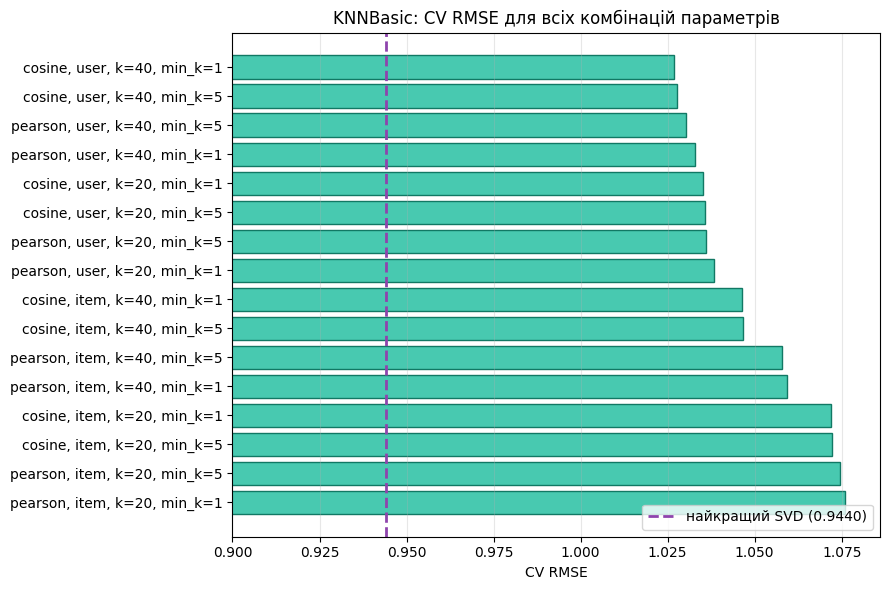

In [10]:
# TODO 5.3 — Виведіть найкращий RMSE, MAE та параметри обох моделей.
# Підказки:
# grid_search_svd.best_score['rmse']
# grid_search_svd.best_params['rmse']
# grid_search_knn.best_score['rmse']

# Ваш код:
# MAE беру для тієї ж комбінації, яка найкраща за RMSE
svd_best_idx = grid_search_svd.best_index['rmse']
knn_best_idx = grid_search_knn.best_index['rmse']

svd_cv_rmse = grid_search_svd.best_score['rmse']
svd_cv_mae = grid_search_svd.cv_results['mean_test_mae'][svd_best_idx]
knn_cv_rmse = grid_search_knn.best_score['rmse']
knn_cv_mae = grid_search_knn.cv_results['mean_test_mae'][knn_best_idx]

print('SVD')
print('  CV RMSE:', round(svd_cv_rmse, 4))
print('  CV MAE :', round(svd_cv_mae, 4))
print('  параметри:', grid_search_svd.best_params['rmse'])

print('\nKNNBasic')
print('  CV RMSE:', round(knn_cv_rmse, 4))
print('  CV MAE :', round(knn_cv_mae, 4))
print('  параметри:', grid_search_knn.best_params['rmse'])

# всі комбінації KNN на одному графіку
labels = [f"{p['sim_options']['name']}, {'user' if p['sim_options']['user_based'] else 'item'}, k={p['k']}, min_k={p['min_k']}"
          for p in knn_cv['params']]
order = knn_cv['mean_test_rmse'].argsort().values

plt.figure(figsize=(9, 6))
plt.barh([labels[i] for i in order], knn_cv['mean_test_rmse'].values[order], color='#48C9B0', edgecolor='#117864')
plt.axvline(svd_cv_rmse, color='#8E44AD', linestyle='--', linewidth=2, label=f'найкращий SVD ({svd_cv_rmse:.4f})')
plt.gca().invert_yaxis()
plt.xlim(0.9, knn_cv['mean_test_rmse'].max() + 0.01)
plt.xlabel('CV RMSE')
plt.title('KNNBasic: CV RMSE для всіх комбінацій параметрів')
plt.legend(loc='lower right')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Аналіз результатів кросвалідації:**

| Модель | Найкращий CV RMSE | CV MAE | Найкращі параметри за RMSE |
|:--|--:|--:|:--|
| SVD | 0.9427 | 0.7437 | n_factors=50, lr_all=0.01, reg_all=0.05 |
| KNNBasic | 1.0267 | 0.8143 | k=40, min_k=1, cosine, user_based=True |

SVD на кросвалідації помітно краща за KNNBasic: RMSE менший приблизно на 0.08, MAE на 0.07. Навіть найгірша комбінація SVD (0.9716) краща за найкращу комбінацію KNN.

Для SVD найкраще спрацювали 50 факторів, більший крок 0.01 і сильніша регуляризація 0.05. Великий крок без сильної регуляризації (reg_all=0.02) навпаки дав найгірші результати, тобто модель перенавчалася. Для KNN усі user-based варіанти виявилися кращими за item-based, а k=40 кращим за k=20. Різниця між cosine і pearson та між min_k=1 і min_k=5 невелика.

## 6. Навчання остаточних моделей

Побудуйте `trainset = train_data.build_full_trainset()`. Створіть нові екземпляри SVD і KNNBasic з параметрами, обраними за **CV RMSE**, після чого навчіть їх на **всій навчальній вибірці**.

In [11]:
# TODO 6.1 — Отримайте best_svd_params і best_knn_params за CV RMSE.
# TODO 6.2 — Створіть trainset із train_data.
# TODO 6.3 — Навчіть best_svd і best_knn.
# Для відтворюваності задайте random_state=42 для SVD.

# Ваш код:
best_svd_params = grid_search_svd.best_params['rmse']
best_knn_params = grid_search_knn.best_params['rmse']

trainset = train_data.build_full_trainset()
print('Користувачів у trainset:', trainset.n_users)
print('Фільмів у trainset:', trainset.n_items)

best_svd = SVD(**best_svd_params, random_state=42)
best_svd.fit(trainset)

best_knn = KNNBasic(**best_knn_params, verbose=False)
best_knn.fit(trainset)

print('\nSVD навчено з параметрами:', best_svd_params)
print('KNNBasic навчено з параметрами:', best_knn_params)

Користувачів у trainset: 943
Фільмів у trainset: 1653

SVD навчено з параметрами: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05}
KNNBasic навчено з параметрами: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}


## 7. Оцінювання на незалежній тестовій вибірці

Отримайте передбачення для `testset` методами `.test()` обох моделей. Обчисліть `RMSE` та `MAE` за допомогою `surprise.accuracy`.

**Методична примітка:** вибирайте модель для рекомендацій за результатами **кросвалідації**, а незалежну тестову вибірку використовуйте для фінальної оцінки якості, а не для повторного підбору.

In [12]:
# TODO 7.1 — Отримайте svd_predictions та knn_predictions.
# TODO 7.2 — Обчисліть svd_rmse, svd_mae, knn_rmse, knn_mae.
# Підказка: accuracy.rmse(predictions, verbose=False)
#           accuracy.mae(predictions, verbose=False)

# Ваш код:
svd_predictions = best_svd.test(testset)
knn_predictions = best_knn.test(testset)

svd_rmse = accuracy.rmse(svd_predictions, verbose=False)
svd_mae = accuracy.mae(svd_predictions, verbose=False)
knn_rmse = accuracy.rmse(knn_predictions, verbose=False)
knn_mae = accuracy.mae(knn_predictions, verbose=False)

print(f'SVD      -> RMSE: {svd_rmse:.4f}, MAE: {svd_mae:.4f}')
print(f'KNNBasic -> RMSE: {knn_rmse:.4f}, MAE: {knn_mae:.4f}')

SVD      -> RMSE: 0.9192, MAE: 0.7234
KNNBasic -> RMSE: 1.0120, MAE: 0.7984


,Model,RMSE,MAE
0,SVD,0.9192,0.7234
1,KNNBasic,1.0120,0.7984


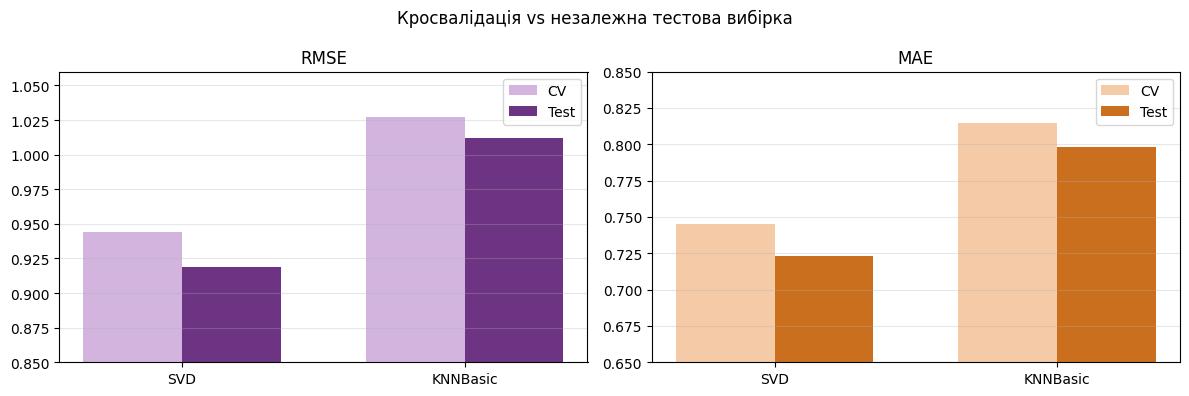

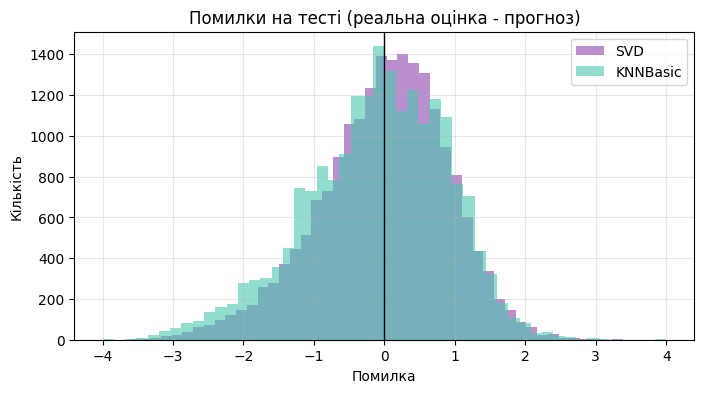

In [13]:
# TODO 7.3 — Сформуйте DataFrame results із колонками:
# Model, RMSE, MAE.
# Відсортуйте за RMSE та покажіть порівняння.

# Ваш код:
results = pd.DataFrame({
    'Model': ['SVD', 'KNNBasic'],
    'RMSE': [svd_rmse, knn_rmse],
    'MAE': [svd_mae, knn_mae]
})
results = results.sort_values('RMSE').reset_index(drop=True)
display(results.round(4))

# порівняння CV і тесту
models = ['SVD', 'KNNBasic']
x = np.arange(len(models))
w = 0.35

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(x - w/2, [svd_cv_rmse, knn_cv_rmse], w, label='CV', color='#D2B4DE')
ax[0].bar(x + w/2, [svd_rmse, knn_rmse], w, label='Test', color='#6C3483')
ax[0].set_title('RMSE')
ax[0].set_ylim(0.85, 1.06)

ax[1].bar(x - w/2, [svd_cv_mae, knn_cv_mae], w, label='CV', color='#F5CBA7')
ax[1].bar(x + w/2, [svd_mae, knn_mae], w, label='Test', color='#CA6F1E')
ax[1].set_title('MAE')
ax[1].set_ylim(0.65, 0.85)

for a in ax:
    a.set_xticks(x)
    a.set_xticklabels(models)
    a.legend()
    a.grid(axis='y', alpha=0.3)

plt.suptitle('Кросвалідація vs незалежна тестова вибірка')
plt.tight_layout()
plt.show()

# розподіл помилок на тесті
svd_err = [p.r_ui - p.est for p in svd_predictions]
knn_err = [p.r_ui - p.est for p in knn_predictions]

plt.figure(figsize=(8, 4))
plt.hist(svd_err, bins=50, alpha=0.6, color='#8E44AD', label='SVD')
plt.hist(knn_err, bins=50, alpha=0.6, color='#48C9B0', label='KNNBasic')
plt.axvline(0, color='black', linewidth=1)
plt.title('Помилки на тесті (реальна оцінка - прогноз)')
plt.xlabel('Помилка')
plt.ylabel('Кількість')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Таблиця тестових результатів:**

| Модель | Test RMSE | Test MAE |
|:--|--:|--:|
| SVD | 0.9192 | 0.7234 |
| KNNBasic | 1.0120 | 0.7984 |

**Порівняння з CV:** Оцінки на тесті трохи кращі, ніж на CV: для SVD RMSE 0.9192 проти 0.9427, для KNN 1.0120 проти 1.0267. Це нормально, бо на кросвалідації модель щоразу вчилася лише на 2/3 навчальних даних (близько 53 тис. оцінок), а фінальна модель вчилася на всіх 80 тис. Різниця невелика (до 0.025), і порядок моделей не змінився, тому результатам CV можна довіряти. SVD краща і на тесті.

## 8. Топ-10 рекомендацій для користувача

1. Оберіть модель із кращим **CV RMSE**.
2. Задайте `user_id` (вихідний приклад використовує `'196'`).
3. Отримайте фільми, які цей користувач уже оцінив у навчальній вибірці.
4. Для решти фільмів обчисліть прогнозований рейтинг `.predict(uid=..., iid=...).est`.
5. Виведіть **10 фільмів із найбільшим прогнозованим рейтингом**.

**Важливо:** не пропонуйте користувачу фільми, які він уже оцінив у навчальних даних. Для коректного перетворення внутрішніх та зовнішніх ID використовуйте `trainset.to_inner_uid()`, `trainset.to_raw_iid()`.

Модель для рекомендацій: SVD
Оцінено у train: 29
Неоцінених фільмів: 1624


,item_id,predicted_rating
1,320,4.490
2,64,4.471
3,480,4.414
4,313,4.402
5,513,4.400
6,483,4.398
7,318,4.392
8,656,4.385
9,22,4.377
10,272,4.376


Перетин з оціненими у train: 0


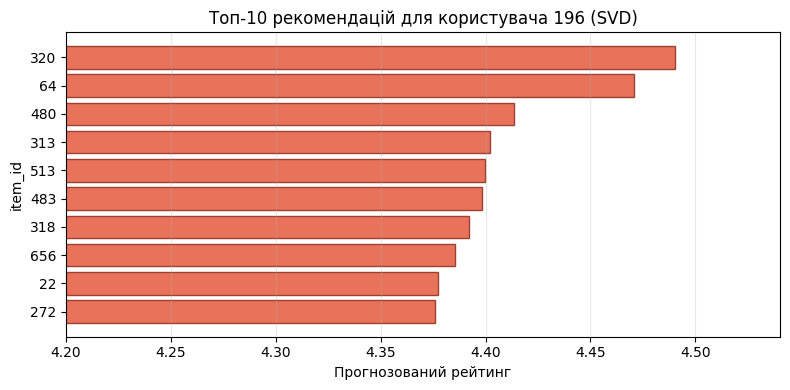

In [14]:
# Початковий ID можна змінити
user_id = '196'

# TODO 8.1 — Визначте найкращу за CV RMSE модель.
# TODO 8.2 — Перевірте, що користувач присутній у trainset.
# TODO 8.3 — Знайдіть неоцінені ним фільми.
# TODO 8.4 — Спрогнозуйте оцінки та покажіть топ-10.
# Бажані колонки результату: item_id, predicted_rating.
# Передбачте ситуацію, коли обраного user_id немає у trainset.

# Ваш код:
if svd_cv_rmse <= knn_cv_rmse:
    best_model, best_name = best_svd, 'SVD'
else:
    best_model, best_name = best_knn, 'KNNBasic'
print('Модель для рекомендацій:', best_name)

try:
    inner_uid = trainset.to_inner_uid(user_id)
except ValueError:
    inner_uid = None
    print(f'Користувача {user_id} немає у trainset, рекомендації побудувати не можна')

if inner_uid is not None:
    # фільми, які користувач уже оцінив у train
    rated_items = set(trainset.to_raw_iid(i) for i, r in trainset.ur[inner_uid])
    all_items = [trainset.to_raw_iid(i) for i in trainset.all_items()]
    not_rated = [i for i in all_items if i not in rated_items]

    print('Оцінено у train:', len(rated_items))
    print('Неоцінених фільмів:', len(not_rated))

    preds = []
    for item in not_rated:
        est = best_model.predict(uid=user_id, iid=item).est
        preds.append((item, est))

    top10 = pd.DataFrame(preds, columns=['item_id', 'predicted_rating'])
    top10 = top10.sort_values('predicted_rating', ascending=False).head(10).reset_index(drop=True)
    top10.index = top10.index + 1
    display(top10.round(3))

    # перевірка, що в топі немає вже оцінених фільмів
    print('Перетин з оціненими у train:', len(set(top10['item_id']) & rated_items))

    plt.figure(figsize=(8, 4))
    plt.barh(top10['item_id'][::-1], top10['predicted_rating'][::-1], color='#E8735A', edgecolor='#A04030')
    plt.xlim(4.2, top10['predicted_rating'].max() + 0.05)
    plt.xlabel('Прогнозований рейтинг')
    plt.ylabel('item_id')
    plt.title(f'Топ-10 рекомендацій для користувача {user_id} ({best_name})')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

## 9. Перевірка виконання

Позначте після реалізації:

- [x] Дані `ml-100k` завантажено та перевірено.
- [x] Є розбиття 80/20 з фіксованим `random_state`.
- [x] `Reader`, `train_data` і `testset` створені коректно.
- [x] GridSearchCV для **обох** моделей виконано лише на `train_data`.
- [x] Для SVD і KNNBasic показано параметри та результати CV.
- [x] Моделі навчено на повній навчальній частині.
- [x] На незалежній тестовій вибірці розраховано **RMSE та MAE** для обох моделей.
- [x] Наведено порівняльну таблицю та інтерпретацію.
- [x] Сформовано топ-10 рекомендацій без уже оцінених фільмів.
- [x] Усі комірки виконуються послідовно після перезапуску середовища.

## 10. Висновки

Заповніть **власними результатами**:

1. Яку модель обрано за кросвалідацією і чому?
2. Які найкращі гіперпараметри отримано для обох моделей?
3. Які підсумкові значення RMSE та MAE на тестовій вибірці?
4. Чи є різниця між результатами CV та тестування?
5. Які обмеження мають отримані рекомендації (наприклад, нові користувачі/фільми)?

**Висновок:** Для рекомендацій я обрала SVD, бо вона має менший CV RMSE (0.9427 проти 1.0267 у KNNBasic). Найкращі параметри SVD: n_factors=50, lr_all=0.01, reg_all=0.05. Для KNNBasic найкращою стала user-based модель з косинусною схожістю, k=40 і min_k=1. На незалежній тестовій вибірці SVD отримала RMSE 0.9192 і MAE 0.7234, KNNBasic RMSE 1.0120 і MAE 0.7984, тобто в середньому SVD помиляється приблизно на 0.72 бала за шкалою від 1 до 5. Тестові оцінки трохи кращі за CV, бо фінальні моделі вчилися на більшій кількості даних, але різниця маленька і висновок про кращу модель не змінюється. Для користувача 196 модель відібрала 10 фільмів з прогнозом від 4.38 до 4.49, серед яких немає вже оцінених ним фільмів. Обмеження: для нових користувачів і нових фільмів модель не має даних, тому прогнозує майже середню оцінку (29 фільмів узагалі не потрапили в train). Також рекомендації будуються лише за ID, без жанрів чи опису, і модель частіше радить популярні фільми з високими середніми оцінками.

---
**Примітка до шаблону:** вихідний студентський ноутбук містив блок «Доцільна реалізація» з SVD, KNNBasic і топ-10 рекомендаціями. Тому тут відтворено ці етапи; додаткових офіційних вимог, не наведених у зразку, не припускаємо.

**Додаткове завдання. Написати власний рекомендаційний алгоритм з нуля**

Я написала спрощену матричну факторизацію (ідея як у SVD з Surprise) на чистому `numpy`, без готових бібліотек.

Ідея така: у кожного користувача і кожного фільму є вектор прихованих ознак. Прогноз оцінки = середня оцінка + зсув користувача + зсув фільму + добуток їхніх векторів. Ці значення підбираються градієнтним спуском. Якщо модель не бачила користувача або фільм, вона ставить майже середню оцінку.

Навчала і перевіряла на тих самих train і test, що й моделі з Surprise.

In [15]:
class MyMF:
    def __init__(self, n_factors=50, lr=0.01, reg=0.05, n_epochs=20, seed=42):
        self.n_factors = n_factors
        self.lr = lr
        self.reg = reg
        self.n_epochs = n_epochs
        self.seed = seed

    def fit(self, df, test_df=None):
        rng = np.random.default_rng(self.seed)
        self.mu = df['rating'].mean()

        # свої індекси для користувачів і фільмів
        self.u_index = {u: k for k, u in enumerate(df['user_id'].unique())}
        self.i_index = {i: k for k, i in enumerate(df['item_id'].unique())}

        self.bu = np.zeros(len(self.u_index))
        self.bi = np.zeros(len(self.i_index))
        self.P = rng.normal(0, 0.1, (len(self.u_index), self.n_factors))
        self.Q = rng.normal(0, 0.1, (len(self.i_index), self.n_factors))

        u_ids = df['user_id'].map(self.u_index).values
        i_ids = df['item_id'].map(self.i_index).values
        r = df['rating'].values

        self.train_hist, self.test_hist = [], []

        for epoch in range(self.n_epochs):
            for k in rng.permutation(len(r)):
                u, i = u_ids[k], i_ids[k]
                err = r[k] - (self.mu + self.bu[u] + self.bi[i] + self.P[u] @ self.Q[i])

                self.bu[u] += self.lr * (err - self.reg * self.bu[u])
                self.bi[i] += self.lr * (err - self.reg * self.bi[i])
                pu = self.P[u].copy()
                self.P[u] += self.lr * (err * self.Q[i] - self.reg * self.P[u])
                self.Q[i] += self.lr * (err * pu - self.reg * self.Q[i])

            train_pred = self.mu + self.bu[u_ids] + self.bi[i_ids] + np.sum(self.P[u_ids] * self.Q[i_ids], axis=1)
            self.train_hist.append(np.sqrt(np.mean((r - train_pred) ** 2)))
            line = f'Епоха {epoch + 1:2d}: train RMSE = {self.train_hist[-1]:.4f}'

            if test_df is not None:
                t_rmse, _ = self.evaluate(test_df)
                self.test_hist.append(t_rmse)
                line += f', test RMSE = {t_rmse:.4f}'
            print(line)
        return self

    def predict(self, user, item):
        pred = self.mu
        u = self.u_index.get(user)
        i = self.i_index.get(item)
        if u is not None:
            pred += self.bu[u]
        if i is not None:
            pred += self.bi[i]
        if u is not None and i is not None:
            pred += self.P[u] @ self.Q[i]
        return min(5, max(1, pred))  # обрізаю до шкали 1..5

    def evaluate(self, df):
        preds = np.array([self.predict(u, i) for u, i in zip(df['user_id'], df['item_id'])])
        err = df['rating'].values - preds
        return np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err))

In [16]:
# беру ті ж параметри, що виявилися найкращими для SVD
my_model = MyMF(n_factors=best_svd_params['n_factors'],
                lr=best_svd_params['lr_all'],
                reg=best_svd_params['reg_all'],
                n_epochs=20)
my_model.fit(train_df, test_df=test_df)

my_rmse, my_mae = my_model.evaluate(test_df)

# найпростіший бейзлайн: завжди середня оцінка з train
mean_err = test_df['rating'].values - train_df['rating'].mean()
base_rmse = np.sqrt(np.mean(mean_err ** 2))
base_mae = np.mean(np.abs(mean_err))

print(f'\nMyMF          -> RMSE: {my_rmse:.4f}, MAE: {my_mae:.4f}')
print(f'Середнє (base) -> RMSE: {base_rmse:.4f}, MAE: {base_mae:.4f}')

Епоха  1: train RMSE = 0.9612, test RMSE = 0.9783
Епоха  2: train RMSE = 0.9313, test RMSE = 0.9585
Епоха  3: train RMSE = 0.9154, test RMSE = 0.9500
Епоха  4: train RMSE = 0.9044, test RMSE = 0.9461
Епоха  5: train RMSE = 0.8947, test RMSE = 0.9435
Епоха  6: train RMSE = 0.8853, test RMSE = 0.9410
Епоха  7: train RMSE = 0.8752, test RMSE = 0.9390
Епоха  8: train RMSE = 0.8642, test RMSE = 0.9367
Епоха  9: train RMSE = 0.8517, test RMSE = 0.9338
Епоха 10: train RMSE = 0.8384, test RMSE = 0.9312
Епоха 11: train RMSE = 0.8236, test RMSE = 0.9291
Епоха 12: train RMSE = 0.8084, test RMSE = 0.9265
Епоха 13: train RMSE = 0.7927, test RMSE = 0.9244
Епоха 14: train RMSE = 0.7767, test RMSE = 0.9230
Епоха 15: train RMSE = 0.7607, test RMSE = 0.9224
Епоха 16: train RMSE = 0.7445, test RMSE = 0.9216
Епоха 17: train RMSE = 0.7283, test RMSE = 0.9204
Епоха 18: train RMSE = 0.7126, test RMSE = 0.9203
Епоха 19: train RMSE = 0.6973, test RMSE = 0.9203
Епоха 20: train RMSE = 0.6825, test RMSE = 0.9204


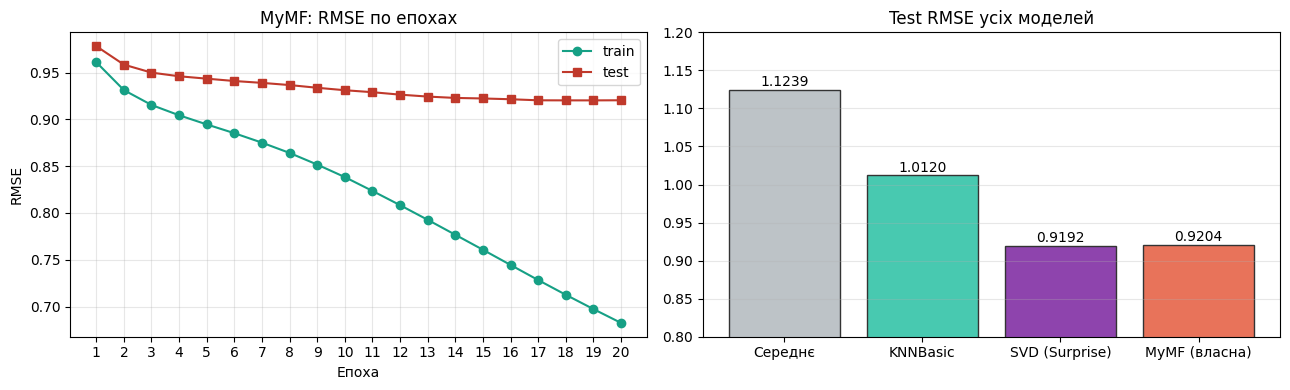

,Model,RMSE,MAE
0,SVD (Surprise),0.9192,0.7234
1,MyMF (власна),0.9204,0.7248
2,KNNBasic,1.0120,0.7984
3,Середнє,1.1239,0.9420


In [17]:
epochs = range(1, len(my_model.train_hist) + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(epochs, my_model.train_hist, marker='o', color='#16A085', label='train')
ax[0].plot(epochs, my_model.test_hist, marker='s', color='#C0392B', label='test')
ax[0].set_title('MyMF: RMSE по епохах')
ax[0].set_xlabel('Епоха')
ax[0].set_xticks(list(epochs))
ax[0].set_ylabel('RMSE')
ax[0].legend()
ax[0].grid(alpha=0.3)

all_results = pd.DataFrame({
    'Model': ['Середнє', 'KNNBasic', 'SVD (Surprise)', 'MyMF (власна)'],
    'RMSE': [base_rmse, knn_rmse, svd_rmse, my_rmse],
    'MAE': [base_mae, knn_mae, svd_mae, my_mae]
})
colors = ['#BDC3C7', '#48C9B0', '#8E44AD', '#E8735A']
ax[1].bar(all_results['Model'], all_results['RMSE'], color=colors, edgecolor='#333333')
for k, v in enumerate(all_results['RMSE']):
    ax[1].text(k, v + 0.005, f'{v:.4f}', ha='center')
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('Test RMSE усіх моделей')
ax[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

display(all_results.sort_values('RMSE').round(4).reset_index(drop=True))

In [18]:
# топ-10 від власної моделі для того ж користувача
my_preds = [(item, my_model.predict(user_id, item)) for item in not_rated]
my_top10 = pd.DataFrame(my_preds, columns=['item_id', 'predicted_rating'])
my_top10 = my_top10.sort_values('predicted_rating', ascending=False).head(10).reset_index(drop=True)
my_top10.index = my_top10.index + 1
display(my_top10.round(3))

common = set(my_top10['item_id']) & set(top10['item_id'])
print('Спільних фільмів з топ-10 від', best_name, ':', len(common), sorted(common, key=int))

,item_id,predicted_rating
1,1194,4.460
2,64,4.450
3,603,4.427
4,318,4.405
5,114,4.402
6,97,4.399
7,98,4.369
8,480,4.362
9,496,4.346
10,483,4.340


Спільних фільмів з топ-10 від SVD : 4 ['64', '318', '480', '483']


**Висновок до додаткового завдання:** Моя модель MyMF отримала на тесті RMSE 0.9204 і MAE 0.7248, це майже як SVD з Surprise (0.9192 і 0.7234), і значно краще за KNNBasic та за простий прогноз середньою оцінкою (RMSE 1.1239). На графіку видно, що train RMSE весь час падає (до 0.68), а test RMSE після 17-18 епохи перестає зменшуватися, тож більше епох тренувати немає сенсу, далі буде перенавчання. Невелика різниця із Surprise пояснюється іншою ініціалізацією та порядком прикладів у SGD. Топ-10 моєї моделі для користувача 196 має 4 спільні фільми з топ-10 від SVD (64, 318, 480, 483), тобто рекомендації схожі, але не однакові.